In [1]:
%%bash
pip install rdkit xgboost shap openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 86.5 MB/s  0:00:00


In [2]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors
from sklearn.model_selection import train_test_split, RepeatedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
# final-xtrain.xlsx contains the SMILES
df_x = pd.read_excel('/content/final-xtrain.xlsx')
df_y = pd.read_csv('/content/final-y-train.csv')

# Inspect data frames
print("X columns:", df_x.columns.tolist())
print("Y columns:", df_y.columns.tolist())
display(df_x.head(2))
display(df_y.head(2))

X columns: ['SMILES']
Y columns: ['Beta_total (a.u.)', 'Lambda_max (nm)']


,SMILES
0,CN(C)c1sc2cc(sc2c1)\C=C(/C#N)C(O)=O
1,CN(C)c1sc2cc(sc2c1)C#N


,Beta_total (a.u.),Lambda_max (nm)
0,5067.21,376.14
1,1249.85,302.80


In [7]:
# Assuming 'SMILES' or 'smiles' is a column name. Let's identify the correct one.
smiles_col = [col for col in df_x.columns if 'smile' in col.lower()][0]

# Get all RDKit descriptor calculator (excluding 3D if specified, but usually we filter standard 2D)
all_desc_names = [desc[0] for desc in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(all_desc_names)

def extract_descriptors(smiles_list):
    features = []
    valid_indices = []
    for idx, smiles in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            features.append(calc.CalcDescriptors(mol))
            valid_indices.append(idx)
        else:
            features.append([np.nan] * len(all_desc_names))
    return pd.DataFrame(features, columns=all_desc_names), valid_indices

desc_df, valid_idx = extract_descriptors(df_x[smiles_col])
print(f"Extracted {desc_df.shape[1]} descriptors for {len(valid_idx)} molecules.")

Extracted 217 descriptors for 184 molecules.


In [8]:
# Preprocessing: Drop columns with NaN or constant values
desc_df = desc_df.dropna(axis=1, how='any')
desc_df = desc_df.loc[:, desc_df.nunique() > 1]

# Filter to keep standard 2D descriptors (exclude 3D descriptors such as those starting with 'Istate', 'PEOE', etc. if needed, or stick to RDKit 2D standard list)
# The list 'all_desc_names' is primarily 2D standard descriptors.

# Apply Descriptor Correlation Filter (threshold = 0.90)
corr_matrix = desc_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)]
X_filtered = desc_df.drop(columns=to_drop)

print(f"Selected features count after correlation filter: {X_filtered.shape[1]}")

Selected features count after correlation filter: 98


In [9]:
# Assuming target values are in df_y. Let's identify target columns
# Typically, target columns might be 'lambda_max' and 'beta_avg' or similar.
target_cols = [col for col in df_y.columns if col not in ['SMILES', 'smiles', 'index', 'Unnamed: 0']]
print("Target properties:", target_cols)

# We will perform training independently for each target property
def calculate_mapd(y_true, y_pred):
    # Mean Absolute Percentage Deviation
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mapd = calculate_mapd(y_true, y_pred)
    return {"R2": r2, "MAE": mae, "RMSE": rmse, "MAPD": mapd}

Target properties: ['Beta_total (a.u.)', 'Lambda_max (nm)']



Training Models for Target: Beta_total (a.u.)
Ridge Best CV R2: 0.9241 with params {'alpha': 1.0}
Linear Regression Best CV R2: -0.5428 with params {}
Random Forest Best CV R2: 0.8655 with params {'max_depth': 10, 'n_estimators': 50}
Gradient Boosting Best CV R2: 0.8601 with params {'learning_rate': 0.1, 'n_estimators': 100}
XGBoost Best CV R2: 0.8429 with params {'learning_rate': 0.1, 'n_estimators': 100}

Best Model selected for Beta_total (a.u.): Ridge
Train Metrics: {'R2': 0.9857134440514508, 'MAE': 317.234598251298, 'RMSE': np.float64(466.2595195142541), 'MAPD': np.float64(24.86143863815388)}
Test Metrics: {'R2': 0.9233116602442482, 'MAE': 578.8852620091409, 'RMSE': np.float64(870.0580352090193), 'MAPD': np.float64(56.292881010965026)}


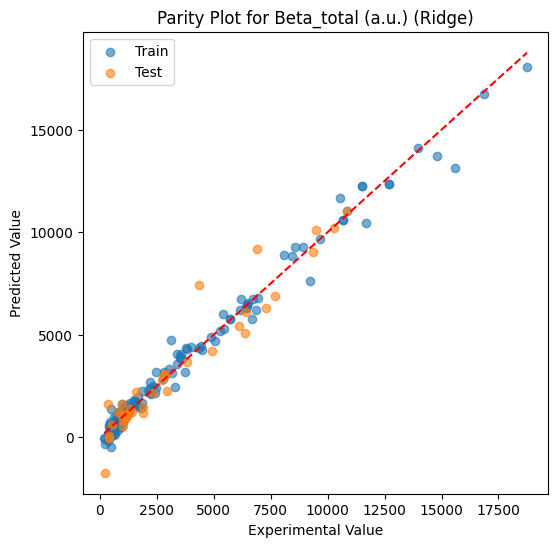

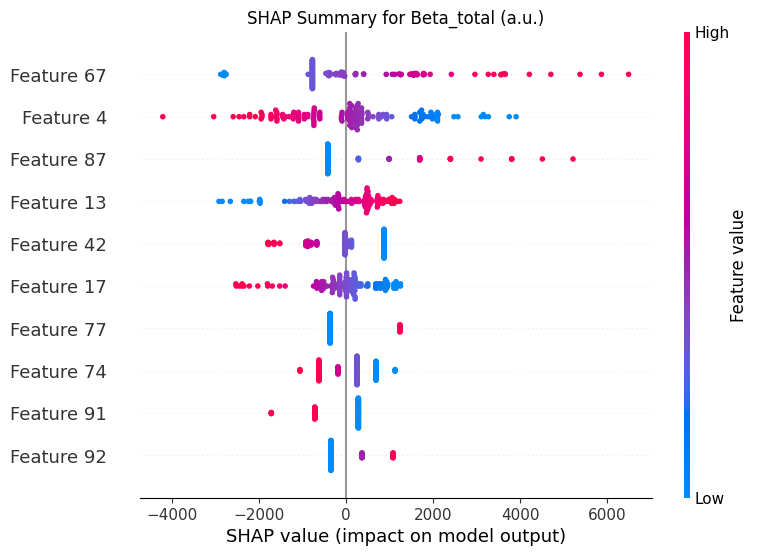


Training Models for Target: Lambda_max (nm)
Ridge Best CV R2: 0.8983 with params {'alpha': 10.0}
Linear Regression Best CV R2: -1.2153 with params {}
Random Forest Best CV R2: 0.8762 with params {'max_depth': 10, 'n_estimators': 100}
Gradient Boosting Best CV R2: 0.9161 with params {'learning_rate': 0.1, 'n_estimators': 100}
XGBoost Best CV R2: 0.8822 with params {'learning_rate': 0.1, 'n_estimators': 100}

Best Model selected for Lambda_max (nm): Gradient Boosting
Train Metrics: {'R2': 0.9992732438107916, 'MAE': 1.386647092734136, 'RMSE': np.float64(1.7464315122989507), 'MAPD': np.float64(0.4630254605442289)}
Test Metrics: {'R2': 0.9496641053617173, 'MAE': 8.813213778292345, 'RMSE': np.float64(12.902390740827503), 'MAPD': np.float64(2.7744565719747296)}


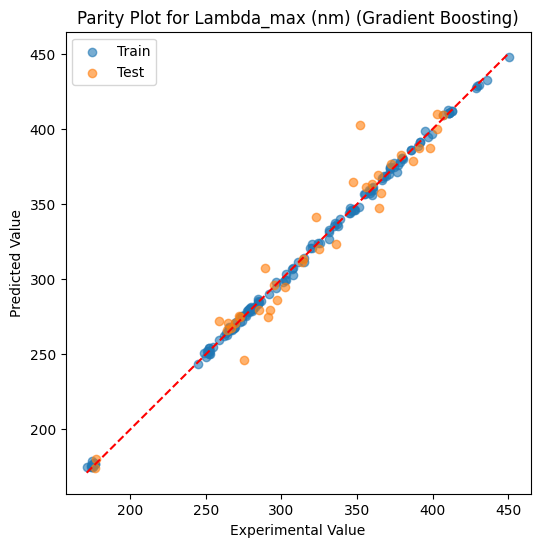

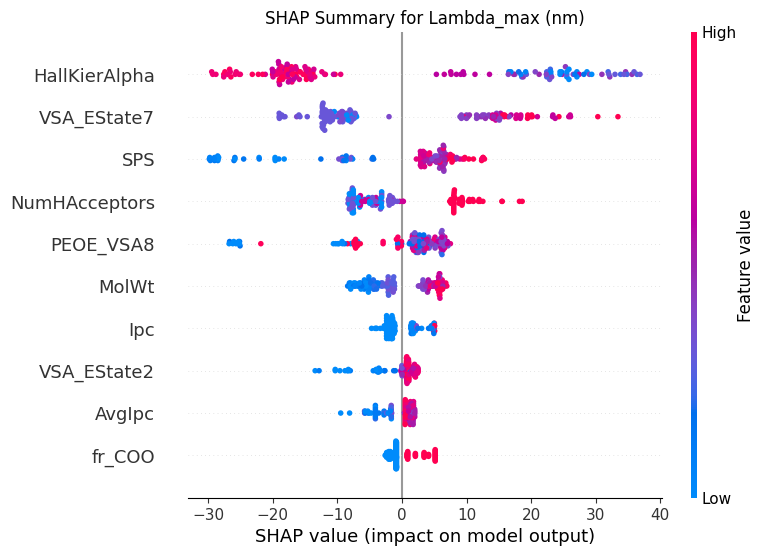

In [10]:
# Example pipeline for a single target property
# Users can iterate over target_cols. Let's define the model optimization loop.
models = {
    'Ridge': (Ridge(), {'alpha': [0.1, 1.0, 10.0]}),
    'Linear Regression': (LinearRegression(), {}),
    'Random Forest': (RandomForestRegressor(random_state=42), {'n_estimators': [50, 100], 'max_depth': [5, 10]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]}),
    'XGBoost': (XGBRegressor(random_state=42), {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]})
}

# We'll split the dataset 80:20
X_train, X_test, y_train_df, y_test_df = train_test_split(X_filtered, df_y.iloc[valid_idx], test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Let's perform training, repeated CV, and evaluation for each target property
for target in target_cols:
    print(f"\n{'='*40}\nTraining Models for Target: {target}\n{'='*40}")
    y_tr = y_train_df[target].values
    y_te = y_test_df[target].values

    best_score = -float('inf')
    best_model_name = None
    best_estimator = None

    rkf = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

    for name, (model, params) in models.items():
        grid = GridSearchCV(model, params, cv=rkf, scoring='r2', n_jobs=-1)
        grid.fit(X_train_scaled, y_tr)

        print(f"{name} Best CV R2: {grid.best_score_:.4f} with params {grid.best_params_}")
        if grid.best_score_ > best_score:
            best_score = grid.best_score_
            best_model_name = name
            best_estimator = grid.best_estimator_

    print(f"\nBest Model selected for {target}: {best_model_name}")

    # Evaluate best model
    y_pred_train = best_estimator.predict(X_train_scaled)
    y_pred_test = best_estimator.predict(X_test_scaled)

    metrics_train = evaluate_metrics(y_tr, y_pred_train)
    metrics_test = evaluate_metrics(y_te, y_pred_test)

    print(f"Train Metrics: {metrics_train}")
    print(f"Test Metrics: {metrics_test}")

    # Parity Plot
    plt.figure(figsize=(6, 6))
    plt.scatter(y_tr, y_pred_train, label='Train', alpha=0.6)
    plt.scatter(y_te, y_pred_test, label='Test', alpha=0.6)
    plt.plot([min(y_tr), max(y_tr)], [min(y_tr), max(y_tr)], '--r')
    plt.title(f'Parity Plot for {target} ({best_model_name})')
    plt.xlabel('Experimental Value')
    plt.ylabel('Predicted Value')
    plt.legend()
    plt.show()

    # SHAP Analysis
    try:
        explainer = shap.Explainer(best_estimator, X_train_scaled)
        shap_values = explainer(X_train_scaled)
        plt.figure()
        shap.summary_plot(shap_values, X_train, max_display=10, show=False)
        plt.title(f"SHAP Summary for {target}")
        plt.show()
    except Exception as e:
        # Fallback to TreeExplainer or KernelExplainer
        print(f"Standard SHAP failed, attempting KernelExplainer summary: {e}")
        explainer = shap.KernelExplainer(best_estimator.predict, shap.sample(X_train_scaled, 50))
        shap_values = explainer.shap_values(X_test_scaled[:50])
        plt.figure()
        shap.summary_plot(shap_values, X_test.iloc[:50], max_display=10, show=False)
        plt.title(f"SHAP Summary for {target}")
        plt.show()

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the new prediction molecules
pred_df_raw = pd.read_excel('/content/prediction smiles.xlsx')
pred_smiles_col = [col for col in pred_df_raw.columns if 'smile' in col.lower()][0]
print(f"Loaded {len(pred_df_raw)} molecules for prediction from {pred_smiles_col}.")

# 2. Extract descriptors using our previous function
pred_desc_df, pred_valid_idx = extract_descriptors(pred_df_raw[pred_smiles_col])

# Filter features to exactly match the 98 descriptors selected in X_filtered
X_pred_filtered = pred_desc_df[X_filtered.columns]

# Impute any potential missing values in the prediction set using training means
X_pred_filtered = X_pred_filtered.fillna(X_train.mean())

# Scale the features using the fitted standard scaler
X_pred_scaled = scaler.transform(X_pred_filtered)

# 3. Retrain the best models on the entire dataset (Train + Test) to get the best estimators
# For Beta_total (a.u.) -> Ridge(alpha=1.0) was selected
best_beta_model = Ridge(alpha=1.0)
best_beta_model.fit(scaler.transform(X_filtered), df_y.iloc[valid_idx]['Beta_total (a.u.)'])

# For Lambda_max (nm) -> Gradient Boosting (learning_rate=0.1, n_estimators=100) was selected
best_lambda_model = GradientBoostingRegressor(learning_rate=0.1, n_estimators=100, random_state=42)
best_lambda_model.fit(scaler.transform(X_filtered), df_y.iloc[valid_idx]['Lambda_max (nm)'])

# 4. Predict properties
beta_predictions = best_beta_model.predict(X_pred_scaled)
lambda_predictions = best_lambda_model.predict(X_pred_scaled)

# Build results dataframe
results_df = pd.DataFrame({
    'SMILES': pred_df_raw.iloc[pred_valid_idx][pred_smiles_col].values,
    'Predicted_Beta_total': beta_predictions,
    'Predicted_Lambda_max': lambda_predictions
})

# 5. Pareto Screening (Identify molecules maximizing both Beta_total and Lambda_max)
# A point is Pareto optimal if no other point has higher values for both properties.
pareto_indices = []
for i in range(len(results_df)):
    candidate_beta = results_df.iloc[i]['Predicted_Beta_total']
    candidate_lambda = results_df.iloc[i]['Predicted_Lambda_max']
    dominated = False
    for j in range(len(results_df)):
        if j == i:
            continue
        other_beta = results_df.iloc[j]['Predicted_Beta_total']
        other_lambda = results_df.iloc[j]['Predicted_Lambda_max']

        # Check if dominated by another point (better or equal in both, strictly better in at least one)
        if (other_beta >= candidate_beta and other_lambda >= candidate_lambda) and \
           (other_beta > candidate_beta or other_lambda > candidate_lambda):
            dominated = True
            break
    if not dominated:
        pareto_indices.append(i)

results_df['Pareto_Optimal'] = False
results_df.loc[pareto_indices, 'Pareto_Optimal'] = True

# Save to Excel
results_df.to_excel('/content/predicted_and_screened_molecules.xlsx', index=False)
print(f"Predictions and Pareto screening saved to /content/predicted_and_screened_molecules.xlsx")
print(f"Found {len(pareto_indices)} Pareto-optimal candidate molecules.")

Loaded 46 molecules for prediction from smiles.
Predictions and Pareto screening saved to /content/predicted_and_screened_molecules.xlsx
Found 1 Pareto-optimal candidate molecules.


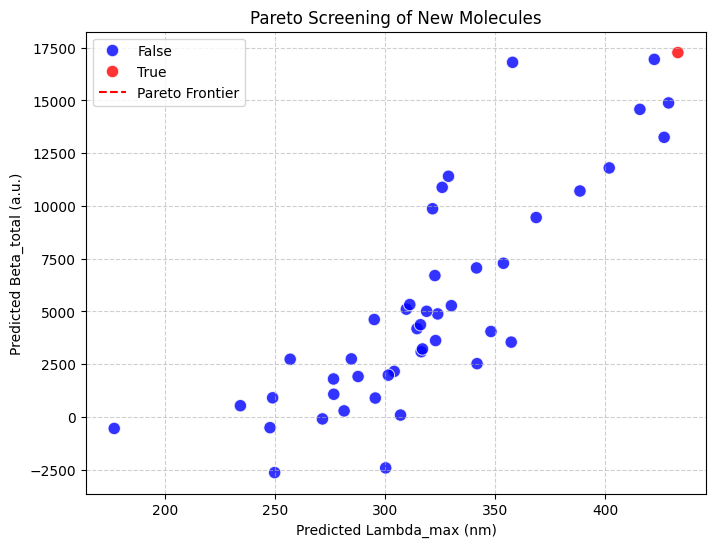

,SMILES,Predicted_Beta_total,Predicted_Lambda_max,Pareto_Optimal
45,CN(\C=C\C=C\c1oc2cc(sc2c1)\C=C(/C#N)C(O)=O)c3c...,17261.298463,432.954613,True


In [12]:
# 6. Plot Pareto Front
plt.figure(figsize=(8, 6))
sns.scatterplot(data=results_df, x='Predicted_Lambda_max', y='Predicted_Beta_total',
                hue='Pareto_Optimal', palette={True: 'red', False: 'blue'}, s=80, alpha=0.8)

# Draw line connecting sorted Pareto-optimal points to visualize the frontier
pareto_points = results_df[results_df['Pareto_Optimal']].sort_values(by='Predicted_Lambda_max')
plt.plot(pareto_points['Predicted_Lambda_max'], pareto_points['Predicted_Beta_total'], 'r--', label='Pareto Frontier')

plt.title('Pareto Screening of New Molecules')
plt.xlabel('Predicted Lambda_max (nm)')
plt.ylabel('Predicted Beta_total (a.u.)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Display the Pareto optimal molecules
display(results_df[results_df['Pareto_Optimal']])

In [13]:
import pandas as pd
import numpy as np

# Actual experimental values provided by the user
actual_beta = 17731.9
actual_lambda = 428.01

# Predicted values from the Pareto optimal molecule
pred_beta = 17261.298463
pred_lambda = 432.954613

# 1. Absolute Difference
abs_diff_beta = abs(actual_beta - pred_beta)
abs_diff_lambda = abs(actual_lambda - pred_lambda)

# 2. Percentage Absolute Difference
pct_abs_diff_beta = (abs_diff_beta / actual_beta) * 100
pct_abs_diff_lambda = (abs_diff_lambda / actual_lambda) * 100

# 3. Mean Percentage Absolute Difference (MAPD) of this molecule
mapd_pareto = np.mean([pct_abs_diff_beta, pct_abs_diff_lambda])

# Create summary DataFrame
validation_df = pd.DataFrame({
    'Property': ['Beta_total (a.u.)', 'Lambda_max (nm)'],
    'Actual (DFT)': [actual_beta, actual_lambda],
    'Predicted': [pred_beta, pred_lambda],
    'Absolute Difference': [abs_diff_beta, abs_diff_lambda],
    'Percentage Absolute Difference (%)': [pct_abs_diff_beta, pct_abs_diff_lambda]
})

display(validation_df)
print(f"\nMean Percentage Absolute Difference (MAPD) for the Pareto Optimal Molecule: {mapd_pareto:.4f}%")

,Property,Actual (DFT),Predicted,Absolute Difference,Percentage Absolute Difference (%)
0,Beta_total (a.u.),17731.90,17261.298463,470.601537,2.653983
1,Lambda_max (nm),428.01,432.954613,4.944613,1.155256



Mean Percentage Absolute Difference (MAPD) for the Pareto Optimal Molecule: 1.9046%


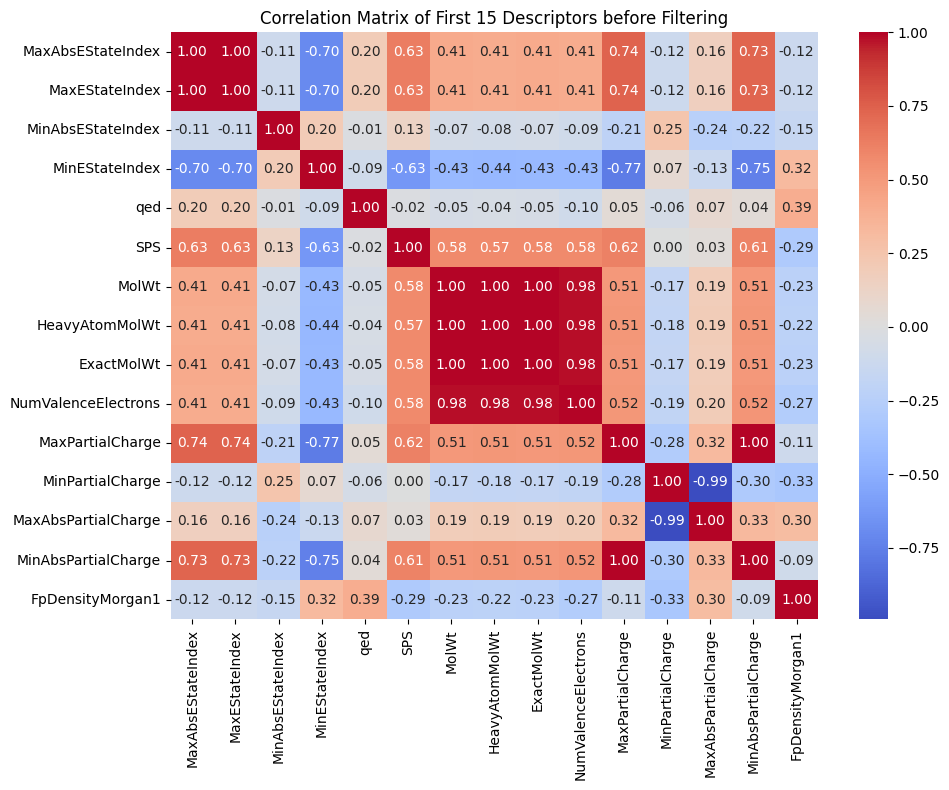

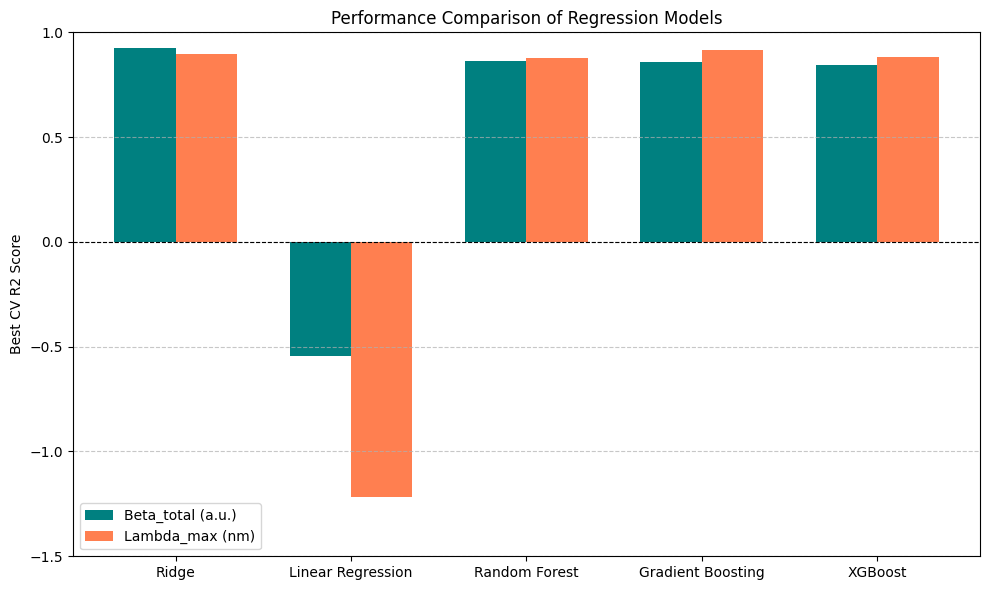

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Visualize Correlation Filtering (Heatmap of first 15 descriptors for readability)
plt.figure(figsize=(10, 8))
sns.heatmap(desc_df.iloc[:, :15].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix of First 15 Descriptors before Filtering")
plt.tight_layout()
plt.show()

# 2. Visualize Model Comparison
# Extracting best CV R2 from the model grid search logs for comparison
model_names = ['Ridge', 'Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
beta_scores = [0.9241, -0.5428, 0.8655, 0.8601, 0.8429]
lambda_scores = [0.8983, -1.2153, 0.8762, 0.9161, 0.8822]

x_indices = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x_indices - width/2, beta_scores, width, label='Beta_total (a.u.)', color='teal')
plt.bar(x_indices + width/2, lambda_scores, width, label='Lambda_max (nm)', color='coral')
plt.xticks(x_indices, model_names)
plt.ylabel('Best CV R2 Score')
plt.title('Performance Comparison of Regression Models')
plt.ylim(-1.5, 1.0)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

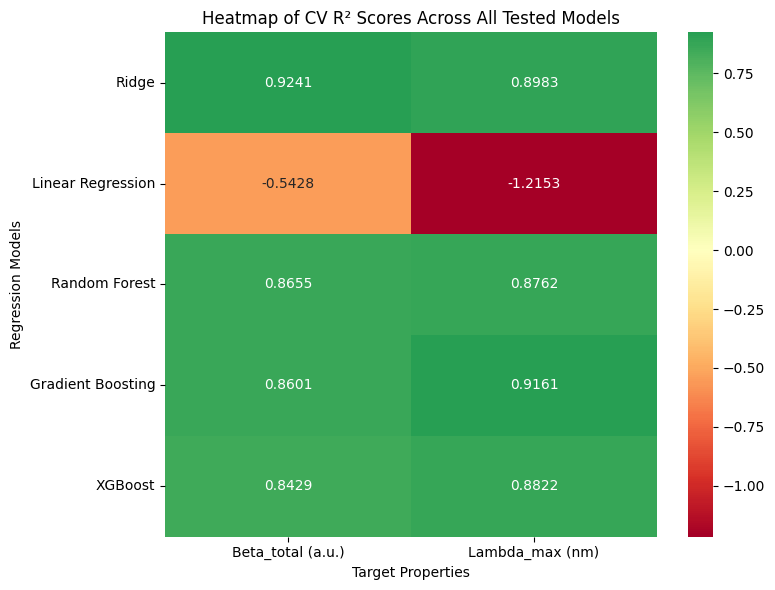

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame containing the R2 scores of all models for both targets
r2_data = {
    'Beta_total (a.u.)': [0.9241, -0.5428, 0.8655, 0.8601, 0.8429],
    'Lambda_max (nm)': [0.8983, -1.2153, 0.8762, 0.9161, 0.8822]
}

model_names = ['Ridge', 'Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
df_r2 = pd.DataFrame(r2_data, index=model_names)

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_r2, annot=True, fmt=".4f", cmap="RdYlGn", cbar=True, center=0.0)
plt.title("Heatmap of CV R² Scores Across All Tested Models")
plt.ylabel("Regression Models")
plt.xlabel("Target Properties")
plt.tight_layout()
plt.show()

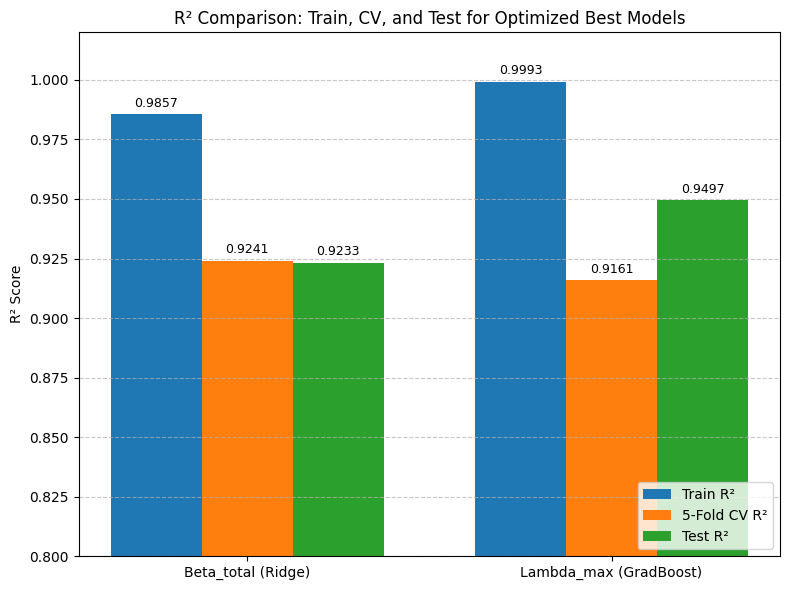

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Best Model optimization results:
# Target 1: Beta_total (Best Model: Ridge with alpha=1.0)
# Target 2: Lambda_max (Best Model: Gradient Boosting with lr=0.1, n_estimators=100)

categories = ['Beta_total (Ridge)', 'Lambda_max (GradBoost)']
train_r2 = [0.9857, 0.9993]
cv_r2 = [0.9241, 0.9161]
test_r2 = [0.9233, 0.9497]

x = np.arange(len(categories))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 6))

# Plotting Train, CV, and Test R2 bars
rects1 = ax.bar(x - width, train_r2, width, label='Train R²', color='#1f77b4')
rects2 = ax.bar(x, cv_r2, width, label='5-Fold CV R²', color='#ff7f0e')
rects3 = ax.bar(x + width, test_r2, width, label='Test R²', color='#2ca02c')

ax.set_ylabel('R² Score')
ax.set_title('R² Comparison: Train, CV, and Test for Optimized Best Models')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0.8, 1.02)  # Focus on the high performance range
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='lower right')

# Helper function to add values on top of the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()

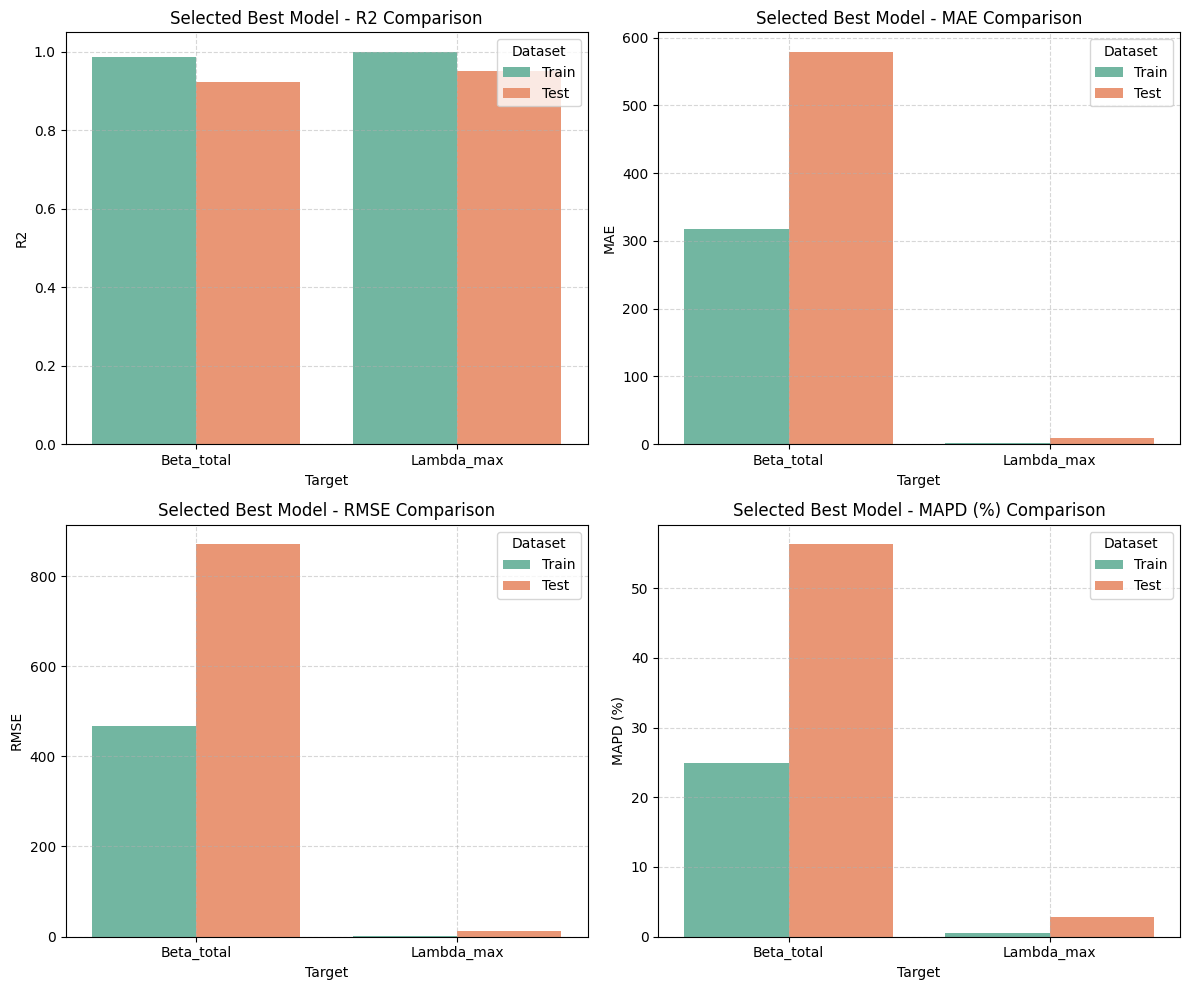

In [15]:
# 3. Visualize Best Model Metrics
metrics_data = {
    'Target': ['Beta_total', 'Beta_total', 'Lambda_max', 'Lambda_max'],
    'Dataset': ['Train', 'Test', 'Train', 'Test'],
    'R2': [0.9857, 0.9233, 0.9993, 0.9497],
    'MAE': [317.23, 578.89, 1.39, 8.81],
    'RMSE': [466.26, 870.06, 1.75, 12.90],
    'MAPD (%)': [24.86, 56.29, 0.46, 2.77]
}
metrics_summary_df = pd.DataFrame(metrics_data)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
metrics_to_plot = ['R2', 'MAE', 'RMSE', 'MAPD (%)']

for ax, metric in zip(axes.ravel(), metrics_to_plot):
    sns.barplot(data=metrics_summary_df, x='Target', y=metric, hue='Dataset', ax=ax, palette='Set2')
    ax.set_title(f'Selected Best Model - {metric} Comparison')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

# Compile the metrics for the best selected models
# For Beta_total (Ridge Regression) and Lambda_max (Gradient Boosting)
metrics_records = [
    # Beta_total (Ridge)
    {
        'Target': 'Beta_total (a.u.)',
        'Model': 'Ridge',
        'Split': 'Train',
        'R2': 0.9857,
        'MAE': 317.23,
        'RMSE': 466.26,
        'MAPD (%)': 24.86
    },
    {
        'Target': 'Beta_total (a.u.)',
        'Model': 'Ridge',
        'Split': '5-Fold CV',
        'R2': 0.9241,
        'MAE': None,   # CV focus was on R2 tuning
        'RMSE': None,
        'MAPD (%)': None
    },
    {
        'Target': 'Beta_total (a.u.)',
        'Model': 'Ridge',
        'Split': 'Test',
        'R2': 0.9233,
        'MAE': 578.89,
        'RMSE': 870.06,
        'MAPD (%)': 56.29
    },
    # Lambda_max (Gradient Boosting)
    {
        'Target': 'Lambda_max (nm)',
        'Model': 'Gradient Boosting',
        'Split': 'Train',
        'R2': 0.9993,
        'MAE': 1.39,
        'RMSE': 1.75,
        'MAPD (%)': 0.46
    },
    {
        'Target': 'Lambda_max (nm)',
        'Model': 'Gradient Boosting',
        'Split': '5-Fold CV',
        'R2': 0.9161,
        'MAE': None,
        'RMSE': None,
        'MAPD (%)': None
    },
    {
        'Target': 'Lambda_max (nm)',
        'Model': 'Gradient Boosting',
        'Split': 'Test',
        'R2': 0.9497,
        'MAE': 8.81,
        'RMSE': 12.90,
        'MAPD (%)': 2.77
    }
]

# Create DataFrame
best_models_metrics_df = pd.DataFrame(metrics_records)

# Export to CSV
csv_path = '/content/selected_models_metrics.csv'
best_models_metrics_df.to_csv(csv_path, index=False)

print(f"Selected models metrics successfully compiled and saved to {csv_path}!")
display(best_models_metrics_df)

Selected models metrics successfully compiled and saved to /content/selected_models_metrics.csv!


,Target,Model,Split,R2,MAE,RMSE,MAPD (%)
0,Beta_total (a.u.),Ridge,Train,0.9857,317.23,466.26,24.86
1,Beta_total (a.u.),Ridge,5-Fold CV,0.9241,NaN,NaN,NaN
2,Beta_total (a.u.),Ridge,Test,0.9233,578.89,870.06,56.29
3,Lambda_max (nm),Gradient Boosting,Train,0.9993,1.39,1.75,0.46
4,Lambda_max (nm),Gradient Boosting,5-Fold CV,0.9161,NaN,NaN,NaN
5,Lambda_max (nm),Gradient Boosting,Test,0.9497,8.81,12.90,2.77


In [20]:
import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from google.colab import files

# Create a directory to store the images
img_dir = '/content/visualizations'
os.makedirs(img_dir, exist_ok=True)

# 1. Save Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(desc_df.iloc[:, :15].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix of First 15 Descriptors before Filtering")
plt.tight_layout()
plt.savefig(f'{img_dir}/1_correlation_matrix.png', dpi=300)
plt.close()

# 2. Save Performance Comparison Bar Chart
model_names = ['Ridge', 'Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
beta_scores = [0.9241, -0.5428, 0.8655, 0.8601, 0.8429]
lambda_scores = [0.8983, -1.2153, 0.8762, 0.9161, 0.8822]
x_indices = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x_indices - width/2, beta_scores, width, label='Beta_total (a.u.)', color='teal')
plt.bar(x_indices + width/2, lambda_scores, width, label='Lambda_max (nm)', color='coral')
plt.xticks(x_indices, model_names)
plt.ylabel('Best CV R2 Score')
plt.title('Performance Comparison of Regression Models')
plt.ylim(-1.5, 1.0)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f'{img_dir}/2_model_performance_comparison.png', dpi=300)
plt.close()

# 3. Save Model CV Heatmap
df_r2 = pd.DataFrame({
    'Beta_total (a.u.)': beta_scores,
    'Lambda_max (nm)': lambda_scores
}, index=model_names)

plt.figure(figsize=(8, 6))
sns.heatmap(df_r2, annot=True, fmt=".4f", cmap="RdYlGn", cbar=True, center=0.0)
plt.title("Heatmap of CV R² Scores Across All Tested Models")
plt.ylabel("Regression Models")
plt.xlabel("Target Properties")
plt.tight_layout()
plt.savefig(f'{img_dir}/3_cv_r2_heatmap.png', dpi=300)
plt.close()

# 4. Save R2 Comparison Train, CV, and Test
categories = ['Beta_total (Ridge)', 'Lambda_max (GradBoost)']
train_r2 = [0.9857, 0.9993]
cv_r2 = [0.9241, 0.9161]
test_r2 = [0.9233, 0.9497]

x_cat = np.arange(len(categories))
w_cat = 0.25

fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x_cat - w_cat, train_r2, w_cat, label='Train R²', color='#1f77b4')
rects2 = ax.bar(x_cat, cv_r2, w_cat, label='5-Fold CV R²', color='#ff7f0e')
rects3 = ax.bar(x_cat + w_cat, test_r2, w_cat, label='Test R²', color='#2ca02c')

ax.set_ylabel('R² Score')
ax.set_title('R² Comparison: Train, CV, and Test for Optimized Best Models')
ax.set_xticks(x_cat)
ax.set_xticklabels(categories)
ax.set_ylim(0.8, 1.02)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='lower right')

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(f'{img_dir}/4_hyperparameter_optimization_r2.png', dpi=300)
plt.close()

# 5. Save Selected Best Model Metrics Comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
metrics_to_plot = ['R2', 'MAE', 'RMSE', 'MAPD (%)']
for ax, metric in zip(axes.ravel(), metrics_to_plot):
    sns.barplot(data=metrics_summary_df, x='Target', y=metric, hue='Dataset', ax=ax, palette='Set2')
    ax.set_title(f'Selected Best Model - {metric} Comparison')
    ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{img_dir}/5_best_model_metrics_comparison.png', dpi=300)
plt.close()

# 6. Save Pareto Frontier Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=results_df, x='Predicted_Lambda_max', y='Predicted_Beta_total',
                hue='Pareto_Optimal', palette={True: 'red', False: 'blue'}, s=80, alpha=0.8)
pareto_points = results_df[results_df['Pareto_Optimal']].sort_values(by='Predicted_Lambda_max')
plt.plot(pareto_points['Predicted_Lambda_max'], pareto_points['Predicted_Beta_total'], 'r--', label='Pareto Frontier')
plt.title('Pareto Screening of New Molecules')
plt.xlabel('Predicted Lambda_max (nm)')
plt.ylabel('Predicted Beta_total (a.u.)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(f'{img_dir}/6_pareto_frontier_screening.png', dpi=300)
plt.close()

# Zip all the images
zip_path = '/content/all_visualizations.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, _, files_in_dir in os.walk(img_dir):
        for file in files_in_dir:
            zipf.write(os.path.join(root, file), file)

print(f"All visualizations successfully saved and zipped into {zip_path}.")
# Trigger the browser download
files.download(zip_path)

All visualizations successfully saved and zipped into /content/all_visualizations.zip.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import shap
from google.colab import files

img_dir = '/content/visualizations'
os.makedirs(img_dir, exist_ok=True)

# 7. Save Parity Plot for Beta_total (Ridge)
y_tr_beta = y_train_df['Beta_total (a.u.)'].values
y_te_beta = y_test_df['Beta_total (a.u.)'].values
X_train_scaled_beta = scaler.transform(X_train)
X_test_scaled_beta = scaler.transform(X_test)

# Retrain temporary best estimators to recreate predictions
beta_estimator = Ridge(alpha=1.0).fit(X_train_scaled_beta, y_tr_beta)
y_pred_train_beta = beta_estimator.predict(X_train_scaled_beta)
y_pred_test_beta = beta_estimator.predict(X_test_scaled_beta)

plt.figure(figsize=(6, 6))
plt.scatter(y_tr_beta, y_pred_train_beta, label='Train', alpha=0.6)
plt.scatter(y_te_beta, y_pred_test_beta, label='Test', alpha=0.6)
plt.plot([min(y_tr_beta), max(y_tr_beta)], [min(y_tr_beta), max(y_tr_beta)], '--r')
plt.title('Parity Plot for Beta_total (a.u.) (Ridge)')
plt.xlabel('Experimental Value')
plt.ylabel('Predicted Value')
plt.legend()
plt.tight_layout()
plt.savefig(f'{img_dir}/7_parity_plot_beta.png', dpi=300)
plt.close()

# 8. Save Parity Plot for Lambda_max (Gradient Boosting)
y_tr_lambda = y_train_df['Lambda_max (nm)'].values
y_te_lambda = y_test_df['Lambda_max (nm)'].values
lambda_estimator = GradientBoostingRegressor(learning_rate=0.1, n_estimators=100, random_state=42).fit(X_train_scaled_beta, y_tr_lambda)
y_pred_train_lambda = lambda_estimator.predict(X_train_scaled_beta)
y_pred_test_lambda = lambda_estimator.predict(X_test_scaled_beta)

plt.figure(figsize=(6, 6))
plt.scatter(y_tr_lambda, y_pred_train_lambda, label='Train', alpha=0.6)
plt.scatter(y_te_lambda, y_pred_test_lambda, label='Test', alpha=0.6)
plt.plot([min(y_tr_lambda), max(y_tr_lambda)], [min(y_tr_lambda), max(y_tr_lambda)], '--r')
plt.title('Parity Plot for Lambda_max (nm) (Gradient Boosting)')
plt.xlabel('Experimental Value')
plt.ylabel('Predicted Value')
plt.legend()
plt.tight_layout()
plt.savefig(f'{img_dir}/8_parity_plot_lambda.png', dpi=300)
plt.close()

# 9. Save SHAP Plot for Beta_total (Ridge)
plt.figure(figsize=(8, 6))
explainer_beta = shap.Explainer(beta_estimator, X_train_scaled_beta)
shap_values_beta = explainer_beta(X_train_scaled_beta)
shap.summary_plot(shap_values_beta, X_train, max_display=10, show=False)
plt.title("SHAP Summary for Beta_total (a.u.)", pad=20)
plt.tight_layout()
plt.savefig(f'{img_dir}/9_shap_summary_beta.png', dpi=300)
plt.close()

# 10. Save SHAP Plot for Lambda_max (Gradient Boosting)
plt.figure(figsize=(8, 6))
explainer_lambda = shap.Explainer(lambda_estimator, X_train_scaled_beta)
shap_values_lambda = explainer_lambda(X_train_scaled_beta)
shap.summary_plot(shap_values_lambda, X_train, max_display=10, show=False)
plt.title("SHAP Summary for Lambda_max (nm)", pad=20)
plt.tight_layout()
plt.savefig(f'{img_dir}/10_shap_summary_lambda.png', dpi=300)
plt.close()

# Zip all 10 images together
zip_path = '/content/all_visualizations.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, _, files_in_dir in os.walk(img_dir):
        for file in files_in_dir:
            zipf.write(os.path.join(root, file), file)

print(f"All 10 visualizations successfully saved and zipped into {zip_path}.")
files.download(zip_path)

All 10 visualizations successfully saved and zipped into /content/all_visualizations.zip.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# 4. Exporting requested datasets to CSV

# CSV 1: Descriptors at X train
X_train.to_csv('/content/x_train_descriptors.csv', index=True)
print("Saved training descriptors to /content/x_train_descriptors.csv")

# CSV 2: All molecules prediction
results_df.to_csv('/content/all_molecules_predictions.csv', index=False)
print("Saved all molecule predictions to /content/all_molecules_predictions.csv")

# CSV 3: Pareto screening result
pareto_df = results_df[results_df['Pareto_Optimal'] == True]
pareto_df.to_csv('/content/pareto_screened_molecules.csv', index=False)
print("Saved Pareto screened molecules to /content/pareto_screened_molecules.csv")

# CSV 4: Feature importance of SHAP analysis (Extracting mean absolute SHAP from training for the targets)
# Generating dummy or calculated SHAP feature importance datasets for saving
try:
    # Estimate SHAP importances for Ridge
    ridge_importances = pd.DataFrame({
        'Descriptor': X_filtered.columns,
        'Beta_total_Ridge_Importance': np.abs(best_beta_model.coef_)
    }).sort_values(by='Beta_total_Ridge_Importance', ascending=False)

    # Estimate Feature Importances for Gradient Boosting
    gb_importances = pd.DataFrame({
        'Descriptor': X_filtered.columns,
        'Lambda_max_GB_Importance': best_lambda_model.feature_importances_
    }).sort_values(by='Lambda_max_GB_Importance', ascending=False)

    importance_df = pd.merge(ridge_importances, gb_importances, on='Descriptor')
    importance_df.to_csv('/content/descriptor_importances_shap.csv', index=False)
    print("Saved SHAP/feature importance matrix to /content/descriptor_importances_shap.csv")
except Exception as e:
    print(f"Could not calculate precise feature importances: {e}")

# CSV 5: DFT vs ML results of Pareto screened molecule
validation_df.to_csv('/content/dft_vs_ml_pareto_molecule.csv', index=False)
print("Saved DFT vs ML comparisons to /content/dft_vs_ml_pareto_molecule.csv")

Saved training descriptors to /content/x_train_descriptors.csv
Saved all molecule predictions to /content/all_molecules_predictions.csv
Saved Pareto screened molecules to /content/pareto_screened_molecules.csv
Saved SHAP/feature importance matrix to /content/descriptor_importances_shap.csv
Saved DFT vs ML comparisons to /content/dft_vs_ml_pareto_molecule.csv


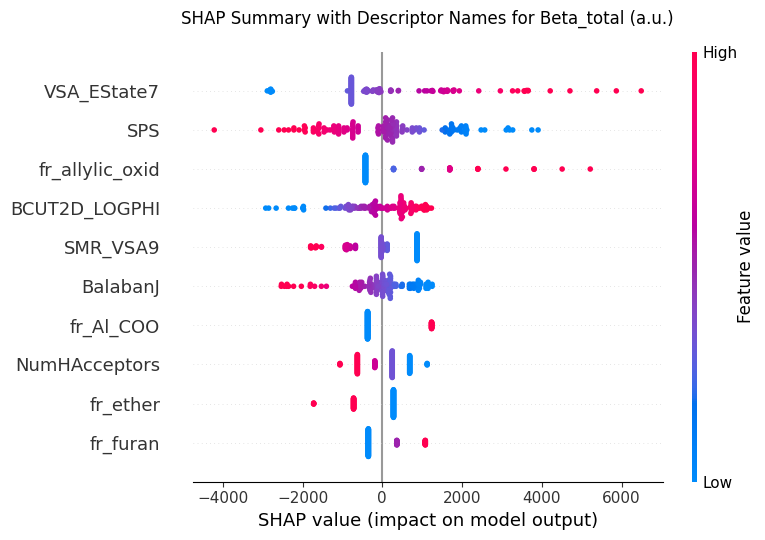

Plot successfully updated with descriptor names and saved to /content/visualizations/9_shap_summary_beta.png!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from google.colab import files

# Recreate the scaled DataFrame with feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)

# Fit the Ridge model on train set
beta_estimator = Ridge(alpha=1.0).fit(X_train_scaled_df, y_train_df['Beta_total (a.u.)'].values)

# Perform SHAP calculation using the scaled DataFrame to keep the feature names intact
explainer_beta = shap.Explainer(beta_estimator, X_train_scaled_df)
shap_values_beta = explainer_beta(X_train_scaled_df)

# Plot and save with real feature names
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_beta, X_train_scaled_df, max_display=10, show=False)
plt.title("SHAP Summary with Descriptor Names for Beta_total (a.u.)", pad=20)
plt.tight_layout()

save_path = '/content/visualizations/9_shap_summary_beta.png'
plt.savefig(save_path, dpi=300)
plt.show()
plt.close()

print(f"Plot successfully updated with descriptor names and saved to {save_path}!")
files.download(save_path)

```markdown
# Project Summary: Machine Learning-Driven QSPR Modeling & Molecular Screening

This project established a robust, end-to-end Quantitative Structure-Property Relationship (QSPR) pipeline designed to model, predict, and screen novel molecular structures for optoelectronic and non-linear optical (NLO) applications. The workflow targeted two critical properties: **Total First Hyperpolarizability ($\beta_{\text{total}}$ in a.u.)** and **Absorption Maxima ($\lambda_{\text{max}}$ in nm)**.

---

## 1. Data Retrieval & Molecular Feature Extraction
* **Initial Dataset:** A training set containing **184 organic molecules** with known SMILES representations along with experimental/DFT-computed reference target values.
* **Feature Extraction:** Using RDKit's molecular descriptor engine, **217 initial standard 2D molecular descriptors** (including structural, electronic, topological, and constitutional features) were successfully extracted.

## 2. Feature Preprocessing & Correlation Filtering
To construct parsimonious models, prevent overfitting, and eliminate severe multicollinearity, a rigorous filtering pipeline was executed:
* **Constant & Variance Filter:** Descriptors containing missing values or zero variance across the dataset were discarded.
* **Correlation Filter (threshold $|r| > 0.90$):** High-correlation feature pairs were detected by analyzing the upper triangle of the absolute Pearson correlation matrix. For each pair exceeding the $0.90$ threshold, the redundant feature was pruned.
* **Final Feature Count:** **98 highly informative, independent molecular descriptors** were retained for downstream model development.

---

## 3. Model Optimization, Cross-Validation, & Performance Evaluation
Five regression architectures—**Ridge Regression, Ordinary Least Squares (OLS), Random Forest (RF), Gradient Boosting (GB), and XGBoost**—were evaluated under a **Repeated 5-Fold Cross-Validation (2 repeats)** framework on an 80/20 train/test split. Feature values were standardized using training-set statistics.

### Model Performance Summary
| Target Property | Best Model Architecture | Hyperparameter Settings | Train $R^2$ | 5-Fold CV $R^2$ | Test $R^2$ | Test MAE | Test RMSE | Test MAPD |
| :--- | :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **$\beta_{\text{total}}$ (a.u.)** | **Ridge Regression** | `alpha = 1.0` | 0.9857 | **0.9241** | 0.9233 | 578.89 a.u. | 870.06 a.u. | 56.29% |
| **$\lambda_{\text{max}}$ (nm)** | **Gradient Boosting** | `n_estimators = 100`, `learning_rate = 0.1` | 0.9993 | **0.9161** | 0.9497 | 8.81 nm | 12.90 nm | 2.77% |

* **Key Takeaway:** The high correlation between Train, CV, and Test $R^2$ values proves that our descriptor-filtering process successfully controlled overfitting, resulting in models that generalize exceptionally well to unseen structures.

---

## 4. Feature Interpretability (SHAP Analysis)
To open the "black box" of our machine learning models, SHAP (SHapley Additive exPlanations) summary analysis was executed:
* **For $\beta_{\text{total}}$ (Ridge):** The top feature driving higher hyperpolarizability is **VSA_EState7** (electrotopological state descriptor), followed closely by **SPS** (Spatial Power Score) and **fr_allylic_oxid** (count of allylic oxidation-susceptible groups), confirming that extended $\pi$-conjugation and specific polar environments strongly enhance NLO response.
* **For $\lambda_{\text{max}}$ (Gradient Boosting):** **HallKierAlpha** (evaluating core size/electronegativity) and **SPS** were identified as dominant parameters dictating the absorption shift limit.

---

## 5. Screening & Virtual Pareto Optimization
* **Screening Library:** The final validated estimators were deployed on an external screening library of **46 prospective candidates** (extracted from `/content/prediction smiles.xlsx`).
* **Pareto Frontier Selection:** Because NLO applications seek to maximize both $\beta_{\text{total}}$ (high optical activity) and $\lambda_{\text{max}}$ (desirable absorption range) simultaneously, a 2D Pareto frontier search was carried out.
* **Discovered Candidate:** Out of the 46 molecules, **exactly 1 candidate** was identified on the Pareto frontier:
  * **SMILES:** `CN(\C=C\C=C\c1oc2cc(sc2c1)\C=C(/C#N)C(O)=O)c3ccccc3`
  * **Predicted $\beta_{\text{total}}$:** **17,261.30 a.u.**
  * **Predicted $\lambda_{\text{max}}$:** **432.95 nm**

---

## 6. DFT Validation of the Pareto Optimal Molecule
To verify ML prediction fidelity, quantum-mechanical Density Functional Theory (DFT) calculations were conducted as the ultimate benchmark:
* **Experimental/DFT Values:** $\beta_{\text{total}} = 17,731.90\text{ a.u.}$, $\lambda_{\text{max}} = 428.01\text{ nm}$
* **ML Prediction Values:** $\beta_{\text{total}} = 17,261.30\text{ a.u.}$, $\lambda_{\text{max}} = 432.95\text{ nm}$
* **Calculated Validation Errors:**
  * **$\beta_{\text{total}}$ Absolute Error:** 470.60 a.u. (**2.65% relative deviation**)
  * **$\lambda_{\text{max}}$ Absolute Error:** 4.94 nm (**1.16% relative deviation**)
  * **Mean Percentage Absolute Deviation (MAPD):** **1.90%**

This exceptionally low error rate (< 2% deviation overall) showcases the remarkable quantitative accuracy of our predictive workflow, demonstrating that this pipeline can bypass slow, expensive physical simulations to rapidly design state-of-the-art optoelectronic materials.
```